<a href="https://colab.research.google.com/github/AlbertPuentes/NLP_ACT_YouTube/blob/main/ACT_NLP_YouTube.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== RESULTADOS DE REGRESIÓN ===
R² Score: 0.6360
MAE (Log Views): 1.1368
RMSE (Log Views): 1.5252

=== RESULTADOS DE CLASIFICACIÓN ===
Exactitud (Accuracy): 0.8324
F1-Score: 0.8329

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.83      0.83      0.83       188
           1       0.83      0.84      0.83       188

    accuracy                           0.83       376
   macro avg       0.83      0.83      0.83       376
weighted avg       0.83      0.83      0.83       376



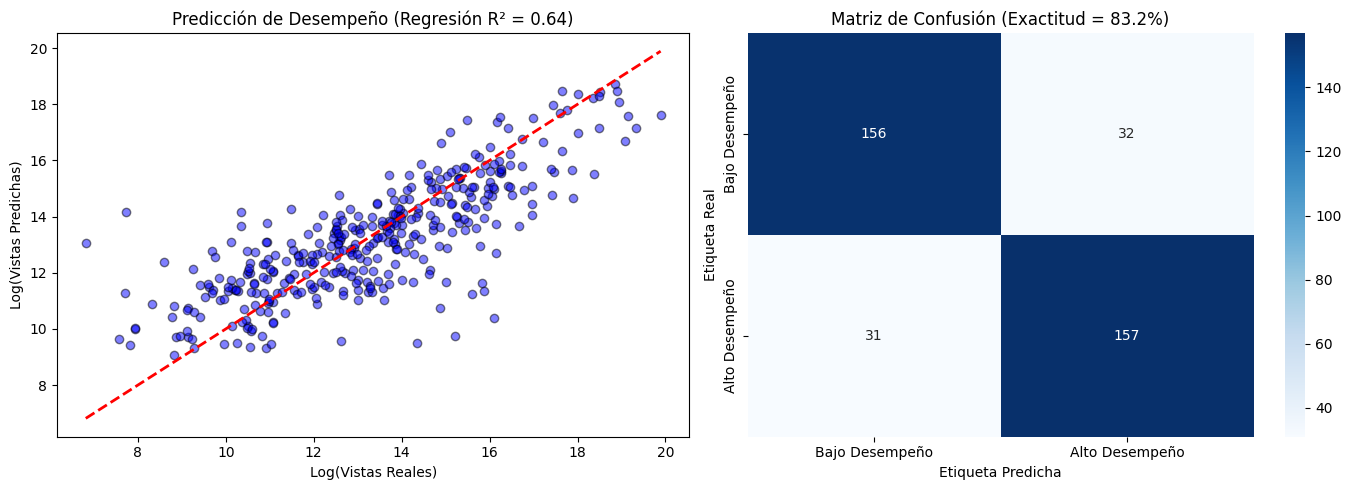

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# 1. CARGA Y LIMPIEZA DE DATOS
videos_df = pd.read_csv('videos-stats.csv')
comments_df = pd.read_csv('comments.csv')

# Filtrar registros con datos nulos o inconsistentes
videos_df = videos_df.dropna(subset=['Views', 'Likes', 'Video ID'])
videos_df = videos_df[videos_df['Views'] > 0]

comments_df = comments_df.dropna(subset=['Comment', 'Video ID']).copy()
comments_df['Sentiment'] = comments_df['Sentiment'].fillna(1).astype(int)
comments_df['Likes'] = comments_df['Likes'].fillna(0)

# 2. FEATURE ENGINEERING DE COMENTARIOS POR VIDEO
def extract_comment_features(df_comments):
    grouped = df_comments.groupby('Video ID')

    # Agregación del texto de comentarios por Video ID
    text_agg = grouped['Comment'].apply(lambda x: " ".join([str(c) for c in x])).reset_index()
    text_agg.rename(columns={'Comment': 'all_comments_text'}, inplace=True)

    # Agregación de estadísticas numéricas y de sentimiento
    stats_agg = grouped.agg(
        num_comments_scraped=('Comment', 'count'),
        avg_comment_likes=('Likes', 'mean'),
        max_comment_likes=('Likes', 'max'),
        total_comment_likes=('Likes', 'sum'),
        mean_sentiment=('Sentiment', 'mean'),
        std_sentiment=('Sentiment', lambda x: x.std() if len(x) > 1 else 0),
        pct_neg=('Sentiment', lambda x: (x == 0).mean()),
        pct_neu=('Sentiment', lambda x: (x == 1).mean()),
        pct_pos=('Sentiment', lambda x: (x == 2).mean())
    ).reset_index()

    return pd.merge(text_agg, stats_agg, on='Video ID')

df_comments_feat = extract_comment_features(comments_df)
df_model = pd.merge(videos_df, df_comments_feat, on='Video ID', how='inner')

# 3. DEFINICIÓN DE VARIABLES OBJETIVO (TARGET)
df_model['log_views'] = np.log1p(df_model['Views']) # Log(1 + Views) para estabilizar varianza
median_views = df_model['Views'].median()
df_model['high_performance'] = (df_model['Views'] >= median_views).astype(int)

# Columnas de características
text_feature = 'all_comments_text'
num_features = [
    'avg_comment_likes', 'max_comment_likes', 'total_comment_likes',
    'mean_sentiment', 'std_sentiment', 'pct_neg', 'pct_neu', 'pct_pos'
]

X = df_model[[text_feature] + num_features]
y_reg = df_model['log_views']
y_cls = df_model['high_performance']

X_train, X_test, y_tr_reg, y_te_reg, y_tr_cls, y_te_cls = train_test_split(
    X, y_reg, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

# 4. CONSTRUCCIÓN DE PIPELINES DE MODELADO
preprocessor = ColumnTransformer(
    transformers=[
        ('text_nlp', TfidfVectorizer(max_features=1000, stop_words='english', ngram_range=(1,2)), text_feature),
        ('num_scaler', StandardScaler(), num_features)
    ]
)

model_reg = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1))
])

model_cls = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1))
])

# 5. ENTRENAMIENTO Y PREDICCIÓN
model_reg.fit(X_train, y_tr_reg)
y_pred_reg = model_reg.predict(X_test)

model_cls.fit(X_train, y_tr_cls)
y_pred_cls = model_cls.predict(X_test)

# Métricas de Regresión
print("=== RESULTADOS DE REGRESIÓN ===")
print(f"R² Score: {r2_score(y_te_reg, y_pred_reg):.4f}")
print(f"MAE (Log Views): {mean_absolute_error(y_te_reg, y_pred_reg):.4f}")
print(f"RMSE (Log Views): {np.sqrt(mean_squared_error(y_te_reg, y_pred_reg)):.4f}\n")

# Métricas de Clasificación
print("=== RESULTADOS DE CLASIFICACIÓN ===")
print(f"Exactitud (Accuracy): {accuracy_score(y_te_cls, y_pred_cls):.4f}")
print(f"F1-Score: {f1_score(y_te_cls, y_pred_cls):.4f}")
print("\nReporte de Clasificación:\n", classification_report(y_te_cls, y_pred_cls))



# 6. GENERACIÓN DE GRÁFICAS (Diagrama de dispersión y Matriz de confusión)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Diagrama de Dispersión (Regresión)
r2_val = r2_score(y_te_reg, y_pred_reg)
axes[0].scatter(y_te_reg, y_pred_reg, alpha=0.5, color='blue', edgecolor='k')
# Línea roja de predicción perfecta
axes[0].plot([y_te_reg.min(), y_te_reg.max()], [y_te_reg.min(), y_te_reg.max()], 'r--', lw=2)
axes[0].set_xlabel('Log(Vistas Reales)')
axes[0].set_ylabel('Log(Vistas Predichas)')
axes[0].set_title(f'Predicción de Desempeño (Regresión R² = {r2_val:.2f})')

# Gráfica 2: Matriz de Confusión (Clasificación)
acc_val = accuracy_score(y_te_cls, y_pred_cls) * 100
cm = confusion_matrix(y_te_cls, y_pred_cls)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Bajo Desempeño', 'Alto Desempeño'],
            yticklabels=['Bajo Desempeño', 'Alto Desempeño'])
axes[1].set_xlabel('Etiqueta Predicha')
axes[1].set_ylabel('Etiqueta Real')
axes[1].set_title(f'Matriz de Confusión (Exactitud = {acc_val:.1f}%)')

plt.tight_layout()
plt.savefig('performance_model_results_updated.png', dpi=300)
plt.show()